# 🧠 Notebook 4: Text Convolutional Neural Network (TextCNN)
**Project**: Sentiment Analysis on YouTube Comments  
**Model**: 1D Convolutional Neural Network (Conv1D + GlobalMaxPooling)  
**Preprocessing**: Keras Tokenizer, Sequence Padding (`max_len=100`)  
**Objective**: Apply 1D convolutional layers to extract local n-gram features from embedded text sequences for multi-class sentiment classification.


In [1]:
# Standard Imports & Deep Learning Setup
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Reproducibility
RANDOM_STATE = 42
tf.random.set_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.20.0


---
## 1. Data Preparation & Stratified Split
Load pre-cleaned YouTube comments and establish 80/20 train/test split.


In [2]:
KAGGLE_PATH = "/kaggle/input/datasets/amaanpoonawala/youtube-comments-sentiment-dataset/youtube_comments_cleaned.csv"
LOCAL_PATH = "youtube_comments_cleaned.csv"

data_path = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(data_path).dropna(subset=['CommentText', 'Sentiment']).reset_index(drop=True)
df['CommentText'] = df['CommentText'].astype(str)

label_mapping = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
reverse_mapping = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
df['label'] = df['Sentiment'].map(label_mapping)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['CommentText'],
    df['label'],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df['label']
)

print(f"Train samples: {len(X_train_raw):,}, Test samples: {len(X_test_raw):,}")


Train samples: 825,780, Test samples: 206,445


---
## 2. Tokenization & Sequence Padding
Converting raw text into integer sequences capped at `MAX_WORDS = 20000` and padded to `MAX_LEN = 100`.


In [3]:
MAX_WORDS = 20000
MAX_LEN = 100
EMBEDDING_DIM = 128

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_raw)

X_train_seq = tokenizer.texts_to_sequences(X_train_raw)
X_test_seq = tokenizer.texts_to_sequences(X_test_raw)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

print(f"Padded Train Matrix Shape: {X_train_pad.shape}")
print(f"Padded Test Matrix Shape: {X_test_pad.shape}")


Padded Train Matrix Shape: (825780, 100)
Padded Test Matrix Shape: (206445, 100)


---
## 3. TextCNN Architecture Definition
Constructing embedding layer, 1D convolution layer for feature extraction, global max pooling, and dense classification layers.


In [4]:
model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    Conv1D(filters=128, kernel_size=5, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1791487234.266909      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791487234.270488      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

---
## 4. Model Training with Validation Split
Fitting the TextCNN model for 8 epochs with a 10% internal validation split.


In [5]:
EPOCHS = 100
BATCH_SIZE = 64

history = model.fit(
    X_train_pad, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    verbose=1
)


Epoch 1/100


2026-10-08 19:20:38.404433: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-08 19:20:38.627438: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


   40/11613 ━━━━━━━━━━━━━━━━━━━━ 45s 4ms/step - accuracy: 0.3565 - loss: 1.0955

I0000 00:00:1791487240.894840      71 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


11604/11613 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6450 - loss: 0.7928

2026-10-08 19:21:26.682673: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-08 19:21:26.900187: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


11613/11613 ━━━━━━━━━━━━━━━━━━━━ 58s 4ms/step - accuracy: 0.6761 - loss: 0.7431 - val_accuracy: 0.7017 - val_loss: 0.6821
Epoch 2/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 48s 4ms/step - accuracy: 0.7212 - loss: 0.6512 - val_accuracy: 0.7061 - val_loss: 0.6829
Epoch 3/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 48s 4ms/step - accuracy: 0.7577 - loss: 0.5736 - val_accuracy: 0.7003 - val_loss: 0.7309
Epoch 4/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 47s 4ms/step - accuracy: 0.7947 - loss: 0.4906 - val_accuracy: 0.6916 - val_loss: 0.8127
Epoch 5/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 48s 4ms/step - accuracy: 0.8257 - loss: 0.4167 - val_accuracy: 0.6867 - val_loss: 0.9373
Epoch 6/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 48s 4ms/step - accuracy: 0.8491 - loss: 0.3601 - val_accuracy: 0.6798 - val_loss: 1.0839
Epoch 7/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 49s 4ms/step - accuracy: 0.8658 - loss: 0.3187 - val_accuracy: 0.6751 - val_loss: 1.2539
Epoch 8/100
11613/11613 ━━━━━━━━━━━━━━━━━━━━ 48s 4ms/step - accuracy: 0.87

---
## 5. Training Curves & Test Set Evaluation
Plotting training vs. validation loss and accuracy curves, followed by final test evaluation.


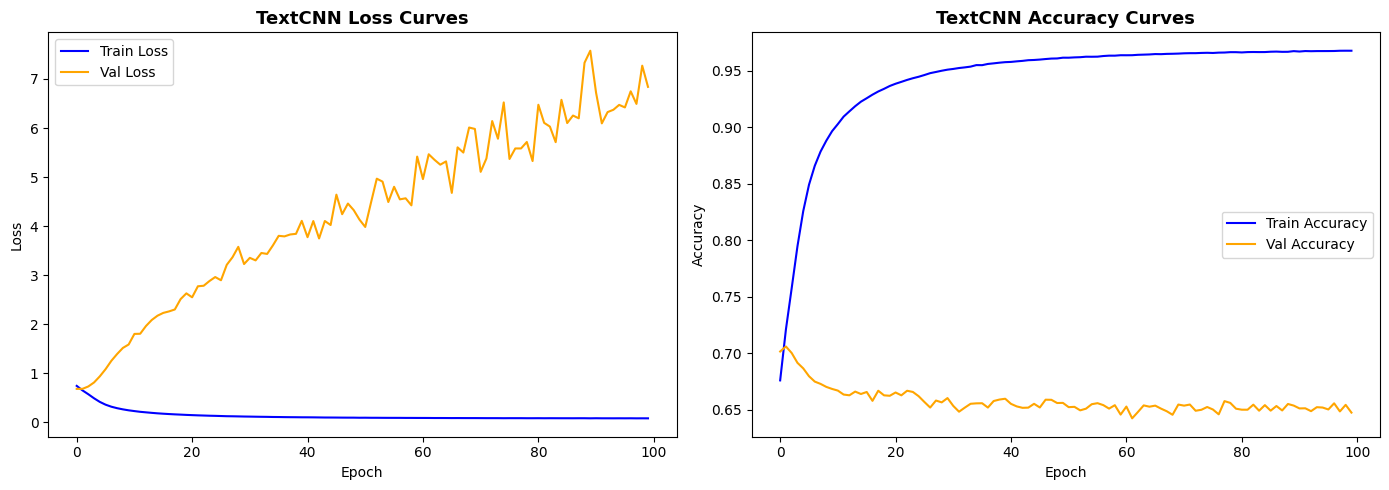

6452/6452 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step
=== TextCNN Test Accuracy: 64.99% ===

Classification Report:
              precision    recall  f1-score   support

    Negative       0.70      0.59      0.64     69215
     Neutral       0.58      0.67      0.62     68567
    Positive       0.70      0.70      0.70     68663

    accuracy                           0.65    206445
   macro avg       0.66      0.65      0.65    206445
weighted avg       0.66      0.65      0.65    206445



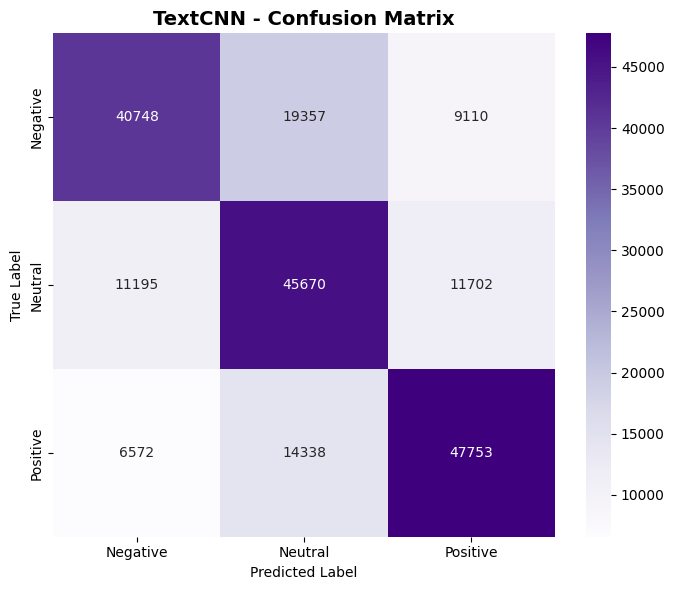

In [6]:
# Plot Training Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss', color='blue')
axes[0].plot(history.history['val_loss'], label='Val Loss', color='orange')
axes[0].set_title('TextCNN Loss Curves', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train Accuracy', color='blue')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy', color='orange')
axes[1].set_title('TextCNN Accuracy Curves', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

# Predictions & Metrics
y_pred_probs = model.predict(X_test_pad)
y_pred = np.argmax(y_pred_probs, axis=1)

acc = accuracy_score(y_test, y_pred)
print(f"=== TextCNN Test Accuracy: {acc * 100:.2f}% ===\n")

class_names = ['Negative', 'Neutral', 'Positive']
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title('TextCNN - Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()
